# AISE4010 Group 11 ? 24-hour lookback, one-hour-ahead forecasting

This standalone notebook combines Stage 1 data exploration, causal preprocessing, seasonal/reference baselines, Ridge and gradient boosting, MLP/CNN models with Stage 2's RNN/LSTM/GRU/TCN models.

**Forecast contract:** each example uses the **previous 24 hourly rows** to predict the **single next hour**. Windows start every hour and overlap. Every measured validation target is scored once; the future target value is never an input. Model and baseline choices use validation only; the final chronological 20% is held out for one final comparison.

In [1]:
import os
import sys
os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')

import copy
import itertools
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.linalg import LinAlgWarning
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.executable)
print('PyTorch:', torch.__version__, '| CUDA build:', torch.version.cuda)
print('CUDA available:', torch.cuda.is_available())
if device.type == 'cuda':
    print('Training device:', torch.cuda.get_device_name(0))
else:
    print('Training device: CPU')
probe = torch.randn(64, 64, device=device)
print('Device smoke test:', (probe @ probe).device)

Python: c:\Users\ahaze\anaconda3\envs\4010-DeepLearning\python.exe
PyTorch: 2.14.1 | CUDA build: 13.4
CUDA available: True
Training device: NVIDIA GeForce RTX 4050 Laptop GPU
Device smoke test: cuda:0


## Load and audit the source data

The source is the one-minute household power dataset. The prediction target is `Global_active_power` in kW. Other electrical measurements are retained only as historical input features; each window ends before the target hour.

In [2]:
df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime').sort_index()
row_missing = df.isna().any(axis=1)
gap_starts = df.index.to_series().diff().gt(pd.Timedelta(minutes=1))

audit = pd.Series({
    'Rows (minute)': len(df),
    'Coverage': f'{df.index.min()} -> {df.index.max()}',
    'Duplicate timestamps': int(df.index.duplicated().sum()),
    'Rows with missing values': int(row_missing.sum()),
    'Columns': len(df.columns),
}, name='Value')
display(audit.to_frame())
display(df.head())

,Value
Rows (minute),2075259
Coverage,2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Duplicate timestamps,0
Rows with missing values,25979
Columns,7


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### Quick temporal overview

Daily and weekly plots are descriptive checks only; model selection remains based on the chronological validation split.

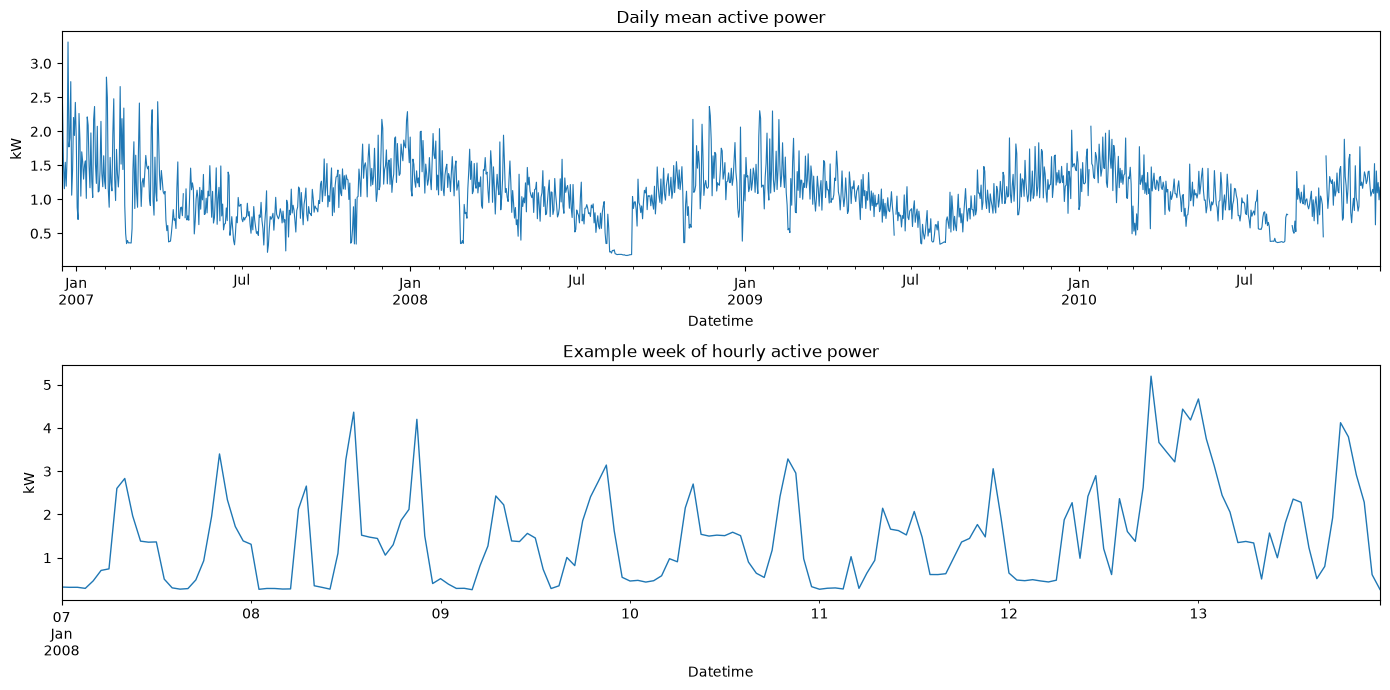

In [3]:
TARGET = 'Global_active_power'
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
daily_mean = df[TARGET].resample('D').mean()
daily_mean.plot(ax=axes[0], lw=0.8, title='Daily mean active power')
week = df[TARGET].resample('h').mean().loc['2008-01-07':'2008-01-13']
week.plot(ax=axes[1], lw=1.0, title='Example week of hourly active power')
axes[0].set_ylabel('kW')
axes[1].set_ylabel('kW')
plt.tight_layout()
plt.show()

## Hourly resampling and causal imputation

Hourly means are retained only when at least 30 minute-level observations exist. Short gaps are forward-filled; longer gaps use the value one week earlier (up to two passes), then the remaining tail is forward-filled. The original missing-target mask is preserved and imputed targets are excluded from model fitting and scoring.

In [4]:
LOOKBACK, HORIZON = 24, 1
DAY, WEEK = 24, 168

counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)
hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()
imputed = imputed.loc[hourly.index]
assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly):,}; imputed target hours: {imputed.sum():,} ({imputed.mean():.2%})')

Hourly rows: 34,589; imputed target hours: 432 (1.25%)


## Calendar/history features and chronological splits

Calendar predictors for the forecast timestamp are known in advance. Historical rolling means and the one-year lag use only earlier measurements. Scalers and all fitted seasonal profiles are learned from training rows only.

In [5]:
features = hourly.copy()
idx = features.index
dow = idx.day_of_week.to_numpy()
year_phase = 2 * np.pi * ((idx.day_of_year.to_numpy() - 1) + idx.hour.to_numpy() / 24) / 365.2425
features['hour_sin'] = np.sin(2 * np.pi * idx.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * dow / 7)
features['dow_cos'] = np.cos(2 * np.pi * dow / 7)
features['is_weekend'] = (dow >= 5).astype(float)
for harmonic in (1, 2):
    features[f'year_sin_{harmonic}'] = np.sin(harmonic * year_phase)
    features[f'year_cos_{harmonic}'] = np.cos(harmonic * year_phase)

past_gap = hourly[TARGET]
causal_mean = past_gap.shift(1).expanding(min_periods=1).mean().fillna(past_gap.iloc[0])
annual_lag = past_gap.reindex(idx - pd.DateOffset(years=1)).to_numpy()
features['GAP_lag_1y_available'] = np.isfinite(annual_lag).astype(float)
features['GAP_lag_1y'] = np.where(np.isfinite(annual_lag), annual_lag, causal_mean.to_numpy())
for days in (1, 7, 28):
    trailing = past_gap.shift(1).rolling(days * 24, min_periods=1).mean()
    features[f'GAP_mean_{days}d'] = trailing.fillna(causal_mean)

FUTURE_CALENDAR_FEATURES = [
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend',
    'year_sin_1', 'year_cos_1', 'year_sin_2', 'year_cos_2',
]
n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}
display(pd.DataFrame([
    {'split': name, 'start': features.index[a], 'end': features.index[b - 1],
     'hours': b - a, 'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
    for name, (a, b) in splits.items()
]).set_index('split'))

,start,end,hours,imputed %
split,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50


## Training-only seasonal profiles and forecast windows

The seasonal reference combines hour-of-week and training-only month residual means. A day-naive reference uses the same hour from the previous day, which is within the 24-hour input window. Each window is 24 past rows and a scalar target at the next timestamp.

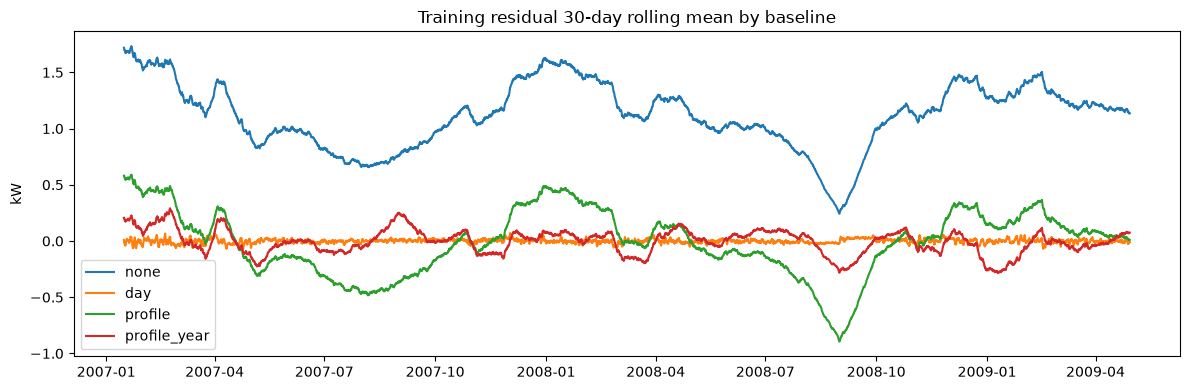

In [6]:
gap = hourly[TARGET].to_numpy(dtype=np.float64)
how = (features.index.day_of_week * 24 + features.index.hour).to_numpy()
profile = pd.Series(gap[:train_end]).groupby(how[:train_end]).mean().reindex(np.arange(WEEK))
weekly_profile = profile.reindex(how).to_numpy()
train_residual = gap[:train_end] - weekly_profile[:train_end]
month_effect = pd.Series(train_residual).groupby(features.index.month[:train_end]).mean()
month_adjustment = pd.Series(features.index.month).map(month_effect).fillna(0.0).to_numpy()
annual_profile = weekly_profile + month_adjustment

day_base = np.empty(n, dtype=np.float64)
day_base[:DAY] = weekly_profile[:DAY]
day_base[DAY:] = gap[:-DAY]
seasonal_base = {
    'none': np.zeros(n, dtype=np.float64),
    'day': day_base,
    'profile': weekly_profile,
    'profile_year': annual_profile,
}

fig, ax = plt.subplots(figsize=(12, 4))
for name, baseline in seasonal_base.items():
    ax.plot(features.index[:train_end], pd.Series(gap[:train_end] - baseline[:train_end]).rolling(30 * DAY).mean(), label=name)
ax.set(title='Training residual 30-day rolling mean by baseline', ylabel='kW')
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
def to_kw(y, split):
    return np.asarray(y).reshape(-1) * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX] + base[split]

def make_windows(start, end):
    targets = np.arange(max(start, LOOKBACK), end)
    X = np.stack([X_all[t - LOOKBACK:t] for t in targets])
    y = X_all[targets, TARGET_IDX]
    future = features.iloc[targets][FUTURE_CALENDAR_FEATURES].to_numpy(dtype=np.float32)
    return X.astype(np.float32), y.astype(np.float32), targets, future

def prepare(variant, drop):
    global FEATURES, TARGET_IDX, x_scaler, X_all, data, base, measured, Y_kw
    global X_train, y_train, future_train, X_val, y_val, future_val
    frame = features.drop(columns=drop).copy()
    target_col = TARGET
    if variant != 'none':
        frame['GAP_resid'] = gap - seasonal_base[variant]
        target_col = 'GAP_resid'
    FEATURES = list(frame.columns)
    TARGET_IDX = FEATURES.index(target_col)
    x_scaler = StandardScaler().fit(frame.iloc[:train_end])
    X_all = x_scaler.transform(frame).astype(np.float32)
    data = {}
    base, measured, Y_kw = {}, {}, {}
    for split_name, (start, end) in splits.items():
        X, y, targets, future = make_windows(start, end)
        data[split_name] = (X, y, targets, future)
        base[split_name] = seasonal_base[variant][targets]
        measured[split_name] = ~imputed.to_numpy()[targets]
        Y_kw[split_name] = gap[targets]
    X_train, y_train, _, future_train = data['train']
    X_val, y_val, _, future_val = data['val']
    assert X_train.shape[1:] == (24, len(FEATURES))
    assert y_train.ndim == 1 and future_train.shape == (len(y_train), len(FUTURE_CALENDAR_FEATURES))
    for split_name, (X, y, targets, _) in data.items():
        assert X.shape[1] == LOOKBACK and np.allclose(Y_kw[split_name], gap[targets])
        assert np.isfinite(X).all() and np.isfinite(y).all()
    return data

COLUMN_SETS = {
    'drop Global_intensity': ['Global_intensity'],
    'drop intensity, voltage, reactive power': ['Global_intensity', 'Voltage', 'Global_reactive_power'],
}

## Stage 1 references, Ridge ablation, and gradient boosting

For one-step forecasts there is no special midnight-start metric: every hourly target is an origin/target pair. Candidate baselines and regressors are ranked by measured-hour validation RMSE across all validation hours.

In [8]:
warnings.filterwarnings('ignore', category=LinAlgWarning)

def evaluate(y_true, y_pred, mask=None):
    error = np.asarray(y_pred).reshape(-1) - np.asarray(y_true).reshape(-1)
    if mask is not None:
        error = error[np.asarray(mask, dtype=bool)]
    return {'MAE (kW)': float(np.mean(np.abs(error))),
            'RMSE (kW)': float(np.sqrt(np.mean(error ** 2)))}

def flat(X):
    return X.reshape(len(X), -1)

ridge_trials = []
for variant in seasonal_base:
    for columns, drop in COLUMN_SETS.items():
        prepare(variant, drop)
        for alpha in (1e2, 1e3, 1e4, 1e5, 1e6):
            start_time = time.perf_counter()
            model = Ridge(alpha=alpha).fit(flat(X_train), y_train)
            elapsed = time.perf_counter() - start_time
            pred_kw = to_kw(model.predict(flat(X_val)), 'val')
            score = evaluate(Y_kw['val'], pred_kw, measured['val'])
            ridge_trials.append({'baseline': variant, 'columns': columns, 'alpha': alpha,
                                 **score, 'train time (s)': elapsed})
ridge_results = pd.DataFrame(ridge_trials).sort_values('RMSE (kW)').reset_index(drop=True)
display(ridge_results.head(12).round(4))
best_ridge_setting = ridge_results.iloc[0]
best_variant = str(best_ridge_setting['baseline'])
best_columns = str(best_ridge_setting['columns'])
best_drop = COLUMN_SETS[best_columns]
prepare(best_variant, best_drop)

# Register simple reference forecasts and the selected Stage 1 Ridge model.
models, model_info = {}, {}
def register(name, predict_fn, params=0, train_seconds=0.0):
    models[name] = predict_fn
    model_info[name] = {'parameters': params, 'train time (s)': train_seconds}

def score_models(split):
    rows = {}
    for name, predict_fn in models.items():
        pred = predict_fn(split)
        rows[name] = evaluate(Y_kw[split], pred, measured[split])
    return pd.DataFrame(rows).T

for variant, label in [('profile', 'Hour-of-week profile'), ('profile_year', 'Seasonal profile + month'), ('day', 'Same hour yesterday')]:
    register(label, lambda s, variant=variant: seasonal_base[variant][data[s][2]])
register('Last-hour persistence', lambda s: gap[data[s][2] - 1])

ridge_alpha = float(best_ridge_setting['alpha'])
start_time = time.perf_counter()
ridge_model = Ridge(alpha=ridge_alpha).fit(flat(X_train), y_train)
ridge_seconds = time.perf_counter() - start_time
register('Ridge', lambda s: to_kw(ridge_model.predict(flat(data[s][0])), s),
         ridge_model.coef_.size + ridge_model.intercept_.size, ridge_seconds)

# Compact tree features retain the full last day, recent means, final feature row, and known target-time calendar.
def gbm_features(X, future):
    target_history = X[:, :, TARGET_IDX]
    return np.hstack([target_history, target_history[:, -6:].mean(1, keepdims=True),
                      target_history.mean(1, keepdims=True), X[:, -1], future])

G_train = gbm_features(data['train'][0], data['train'][3])
G_val = gbm_features(data['val'][0], data['val'][3])
gbm_trials = []
gbm_best = None
for learning_rate, leaves in itertools.product((0.05, 0.1), (15, 31)):
    start_time = time.perf_counter()
    model = HistGradientBoostingRegressor(
        learning_rate=learning_rate, max_leaf_nodes=leaves, max_iter=250,
        early_stopping=True, random_state=SEED,
    ).fit(G_train[measured['train']], y_train[measured['train']])
    elapsed = time.perf_counter() - start_time
    pred_kw = to_kw(model.predict(G_val), 'val')
    score = evaluate(Y_kw['val'], pred_kw, measured['val'])
    gbm_trials.append({'learning_rate': learning_rate, 'max_leaf_nodes': leaves, **score, 'train time (s)': elapsed})
    if gbm_best is None or score['RMSE (kW)'] < gbm_best[0]:
        gbm_best = (score['RMSE (kW)'], model, elapsed)
display(pd.DataFrame(gbm_trials).sort_values('RMSE (kW)').round(4))
gbm_model, gbm_seconds = gbm_best[1], gbm_best[2]
register('HistGradientBoosting',
         lambda s: to_kw(gbm_model.predict(gbm_features(data[s][0], data[s][3])), s),
         gbm_model.n_iter_, gbm_seconds)
display(score_models('val').sort_values('RMSE (kW)').round(4))

,baseline,columns,alpha,MAE (kW),RMSE (kW),train time (s)
0,profile_year,drop Global_intensity,100.0,0.3602,0.5064,0.1435
1,profile,drop Global_intensity,100.0,0.3603,0.5064,0.1231
2,profile,"drop intensity, voltage, reactive power",100.0,0.3589,0.5069,0.0913
3,profile_year,"drop intensity, voltage, reactive power",100.0,0.3591,0.5070,0.0931
4,profile_year,drop Global_intensity,1000.0,0.3619,0.5076,0.1112
5,profile,drop Global_intensity,1000.0,0.3623,0.5078,0.1271
6,profile,"drop intensity, voltage, reactive power",1000.0,0.3611,0.5086,0.0925
7,profile_year,"drop intensity, voltage, reactive power",1000.0,0.3612,0.5086,0.0869
8,day,drop Global_intensity,100.0,0.3671,0.5157,0.1073
9,none,drop Global_intensity,100.0,0.3684,0.5162,0.2452


,learning_rate,max_leaf_nodes,MAE (kW),RMSE (kW),train time (s)
0,0.05,15,0.3340,0.4792,5.2185
1,0.05,31,0.3332,0.4802,3.4880
3,0.10,31,0.3345,0.4806,0.9895
2,0.10,15,0.3357,0.4817,0.6844


,MAE (kW),RMSE (kW)
HistGradientBoosting,0.3340,0.4792
Ridge,0.3602,0.5064
Seasonal profile + month,0.4796,0.6369
Last-hour persistence,0.4179,0.6386
Hour-of-week profile,0.5144,0.6946
Same hour yesterday,0.5843,0.8662


## Stage 1 MLP/CNN and Stage 2 recurrent/TCN models

All neural families output one residual for the next hour and receive known calendar values for that target time. A separate trainable `hour_cos` contribution is initialized by a least-squares slope on **measured training residual targets only**. The coefficient is trainable after initialization; it is not fitted from validation/test data.

In [9]:
HOUR_COS_IDX = FUTURE_CALENDAR_FEATURES.index('hour_cos')
train_cos = data['train'][3][measured['train'], HOUR_COS_IDX]
train_resid = y_train[measured['train']]
centered_cos = train_cos - train_cos.mean()
centered_resid = train_resid - train_resid.mean()
cos_energy = np.dot(centered_cos, centered_cos)
if cos_energy <= 0:
    raise ValueError('Training hour_cos has no variance; cannot initialize its coefficient')
INITIAL_DAILY_COS_WEIGHT = float(np.dot(centered_cos, centered_resid) / cos_energy)
print(f'Train-only initial hour_cos coefficient (standardized residual units): {INITIAL_DAILY_COS_WEIGHT:.4f}')

BATCH = 128
MAX_EPOCHS, PATIENCE = 180, 18

class MLP(nn.Module):
    def __init__(self, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        blocks = [nn.Flatten()]
        width = LOOKBACK * len(FEATURES) + len(FUTURE_CALENDAR_FEATURES)
        for _ in range(layers):
            blocks.extend([nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(dropout)])
            width = hidden
        self.net = nn.Sequential(*blocks, nn.Linear(width, 1))
        self.daily_cos_weight = nn.Parameter(torch.tensor(INITIAL_DAILY_COS_WEIGHT))

    def forward(self, x, future):
        combined = torch.cat([x.flatten(1), future], dim=1)
        correction = self.net(combined).squeeze(-1)
        return correction + self.daily_cos_weight * future[:, HOUR_COS_IDX]

class CNN(nn.Module):
    def __init__(self, filters=32, kernel=3, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(len(FEATURES), filters, kernel, padding='same'), nn.GroupNorm(8, filters), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(filters, filters, kernel, padding='same'), nn.GroupNorm(8, filters), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(filters * (LOOKBACK // 4) + len(FUTURE_CALENDAR_FEATURES), filters),
            nn.ReLU(), nn.Linear(filters, 1),
        )
        self.daily_cos_weight = nn.Parameter(torch.tensor(INITIAL_DAILY_COS_WEIGHT))

    def forward(self, x, future):
        encoded = self.encoder(x.transpose(1, 2)).flatten(1)
        correction = self.head(torch.cat([encoded, future], dim=1)).squeeze(-1)
        return correction + self.daily_cos_weight * future[:, HOUR_COS_IDX]

class RecurrentForecaster(nn.Module):
    def __init__(self, cell='GRU', hidden=64, layers=1, dropout=0.1):
        super().__init__()
        recurrent = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        self.encoder = recurrent(len(FEATURES), hidden, num_layers=layers, batch_first=True,
                                 dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden + len(FUTURE_CALENDAR_FEATURES), hidden),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
        self.daily_cos_weight = nn.Parameter(torch.tensor(INITIAL_DAILY_COS_WEIGHT))

    def forward(self, x, future):
        encoded, _ = self.encoder(x)
        correction = self.head(torch.cat([encoded[:, -1], future], dim=1)).squeeze(-1)
        return correction + self.daily_cos_weight * future[:, HOUR_COS_IDX]

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel, dilation):
        super().__init__()
        self.left = (kernel - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel, padding=self.left, dilation=dilation)

    def forward(self, x):
        out = self.conv(x)
        return out[..., :-self.left] if self.left else out

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, width, kernel, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, width, kernel, dilation)
        self.conv2 = CausalConv1d(width, width, kernel, dilation)
        self.skip = nn.Conv1d(in_channels, width, 1) if in_channels != width else nn.Identity()
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        residual = self.skip(x)
        out = self.dropout(self.activation(self.conv1(x)))
        out = self.dropout(self.activation(self.conv2(out)))
        return self.activation(out + residual)

class TCN(nn.Module):
    def __init__(self, hidden=32, layers=4, kernel=3, dropout=0.1):
        super().__init__()
        blocks = []
        in_channels = len(FEATURES)
        for level in range(layers):
            blocks.append(TemporalBlock(in_channels, hidden, kernel, 2 ** level, dropout))
            in_channels = hidden
        self.encoder = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Linear(hidden + len(FUTURE_CALENDAR_FEATURES), hidden),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
        self.daily_cos_weight = nn.Parameter(torch.tensor(INITIAL_DAILY_COS_WEIGHT))

    def forward(self, x, future):
        encoded = self.encoder(x.transpose(1, 2))[:, :, -1]
        correction = self.head(torch.cat([encoded, future], dim=1)).squeeze(-1)
        return correction + self.daily_cos_weight * future[:, HOUR_COS_IDX]

BUILDERS = {
    'MLP': lambda **cfg: MLP(**cfg),
    'CNN': lambda **cfg: CNN(**cfg),
    'RNN': lambda **cfg: RecurrentForecaster(cell='RNN', **cfg),
    'LSTM': lambda **cfg: RecurrentForecaster(cell='LSTM', **cfg),
    'GRU': lambda **cfg: RecurrentForecaster(cell='GRU', **cfg),
    'TCN': lambda **cfg: TCN(**cfg),
}

Train-only initial hour_cos coefficient (standardized residual units): 0.0004


In [ ]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def fit_model(build, train, val, train_mask, val_mask, lr, batch_size=BATCH,
              weight_decay=1e-2, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    set_seed()
    model = build().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    X_tr, y_tr, C_tr = (torch.as_tensor(a, device=device) for a in train)
    X_va, y_va, C_va = (torch.as_tensor(a, device=device) for a in val)
    train_mask = torch.as_tensor(train_mask, dtype=torch.bool, device=device)
    val_mask = torch.as_tensor(val_mask, dtype=torch.bool, device=device)
    if train_mask.shape != y_tr.shape or val_mask.shape != y_va.shape:
        raise ValueError('Training/validation masks must match scalar target shapes')
    if not train_mask.any() or not val_mask.any():
        raise ValueError('Training and validation masks must each contain measured targets')
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start_time = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total_loss, total_count = 0.0, 0
        for indices in torch.randperm(len(X_tr), device=device).split(batch_size):
            valid = train_mask[indices]
            if not valid.any():
                continue
            optimizer.zero_grad()
            prediction = model(X_tr[indices], C_tr[indices])
            loss = nn.functional.mse_loss(prediction[valid], y_tr[indices][valid])
            loss.backward()
            optimizer.step()
            total_loss += loss.detach().item() * int(valid.sum())
            total_count += int(valid.sum())
        model.eval()
        squared_error, count = 0.0, 0
        with torch.no_grad():
            for start in range(0, len(X_va), 1024):
                end = start + 1024
                pred = model(X_va[start:end], C_va[start:end])
                valid = val_mask[start:end]
                squared_error += (pred[valid] - y_va[start:end][valid]).square().sum().item()
                count += int(valid.sum())
        if count == 0:
            raise ValueError('Validation mask contains no measured targets')
        train_loss, val_loss = total_loss / total_count, squared_error / count
        history['train'].append(train_loss)
        history['val'].append(val_loss)
        if val_loss < best_loss:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start_time

def predict_neural(model, X, calendar):
    model.eval()
    with torch.no_grad():
        outputs = [model(torch.as_tensor(Xb, device=device), torch.as_tensor(Cb, device=device)).cpu()
                   for Xb, Cb in zip(np.array_split(X, max(1, int(np.ceil(len(X) / 1024)))),
                                     np.array_split(calendar, max(1, int(np.ceil(len(calendar) / 1024))))) if len(Xb)]
    return torch.cat(outputs).numpy().reshape(-1)

# Run each architecture once, using the second learning rate.
learning_rates = [2.4e-4]
architecture_space = {
    'MLP': [
        {'hidden': h, 'layers': depth, 'dropout': drop}
        for h, depth, drop in [(32, 1, 0.0), (32, 2, 0.2), (64, 1, 0.1), (64, 2, 0.2), (128, 1, 0.1), (128, 2, 0.3)]
    ],
    'CNN': [
        {'filters': f, 'kernel': k, 'dropout': d}
        for f, k, d in [(16, 3, 0.0), (16, 5, 0.1), (32, 3, 0.1), (32, 5, 0.2), (64, 3, 0.1), (64, 5, 0.2)]
    ],
    'RNN': [{'hidden': h, 'layers': depth, 'dropout': d} for h, depth, d in [(32,1,0.0),(64,1,0.0),(64,1,0.1),(64,2,0.1),(128,1,0.1),(128,2,0.2)]],
    'LSTM': [{'hidden': h, 'layers': depth, 'dropout': d} for h, depth, d in [(32,1,0.0),(64,1,0.0),(64,1,0.1),(64,2,0.1),(128,1,0.1),(128,2,0.2)]],
    'GRU': [{'hidden': h, 'layers': depth, 'dropout': d} for h, depth, d in [(32,1,0.0),(64,1,0.0),(64,1,0.1),(64,2,0.1),(128,1,0.1),(128,2,0.2)]],
    'TCN': [
        {'hidden': h, 'layers': depth, 'kernel': 3, 'dropout': d}
        for h, depth, d in [(16,3,0.0),(16,4,0.1),(32,3,0.1),(32,4,0.1),(64,3,0.1),(64,4,0.2)]
    ],
}
train_arrays = (data['train'][0], data['train'][1], data['train'][3])
val_arrays = (data['val'][0], data['val'][1], data['val'][3])
neural_best, neural_trials = {}, []
for family, builder in BUILDERS.items():
    family_best = None
    configs = [{**arch, 'lr': lr} for arch in architecture_space[family] for lr in learning_rates]
    for trial, config in enumerate(configs, 1):
        model_cfg = {k: v for k, v in config.items() if k != 'lr'}
        model, history, seconds = fit_model(
            lambda builder=builder, model_cfg=model_cfg: builder(**model_cfg),
            train_arrays, val_arrays, measured['train'], measured['val'], lr=config['lr'])
        pred = predict_neural(model, data['val'][0], data['val'][3])
        score = evaluate(Y_kw['val'], to_kw(pred, 'val'), measured['val'])
        row = {'family': family, **config, **score, 'epochs': len(history['val']), 'train time (s)': seconds,
               'parameters': sum(p.numel() for p in model.parameters())}
        neural_trials.append(row)
        if family_best is None or score['RMSE (kW)'] < family_best['RMSE (kW)']:
            family_best = {**row, 'model': model, 'history': history, 'model_config': model_cfg}
        print(f'{family} trial {trial}/{len(configs)}: validation RMSE={score["RMSE (kW)"]:.4f} kW')
    neural_best[family] = family_best

neural_results = pd.DataFrame([{k: v for k, v in row.items() if k not in ('model', 'history', 'model_config')}
                               for row in neural_best.values()]).set_index('family').sort_values('RMSE (kW)')
display(neural_results.round(4))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (family, best) in zip(axes.flat, neural_best.items()):
    ax.plot(best['history']['train'], label='train')
    ax.plot(best['history']['val'], label='validation')
    ax.set(title=family, xlabel='Epoch', ylabel='Measured-target MSE')
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

MLP trial 1/8: validation RMSE=0.5052 kW
MLP trial 2/8: validation RMSE=0.5068 kW
MLP trial 3/8: validation RMSE=0.5072 kW
MLP trial 4/8: validation RMSE=0.5100 kW
MLP trial 5/8: validation RMSE=0.5016 kW
MLP trial 6/8: validation RMSE=0.5003 kW
MLP trial 7/8: validation RMSE=0.5009 kW
MLP trial 8/8: validation RMSE=0.5023 kW
CNN trial 1/8: validation RMSE=0.5237 kW
CNN trial 2/8: validation RMSE=0.5234 kW
CNN trial 3/8: validation RMSE=0.5167 kW
CNN trial 4/8: validation RMSE=0.5074 kW
CNN trial 5/8: validation RMSE=0.5188 kW
CNN trial 6/8: validation RMSE=0.5181 kW
CNN trial 7/8: validation RMSE=0.5125 kW
CNN trial 8/8: validation RMSE=0.5087 kW
RNN trial 1/8: validation RMSE=0.4923 kW
RNN trial 2/8: validation RMSE=0.4914 kW


## Validation comparison and final held-out test

All candidate selection is completed using validation data. Each model forecasts the next hour at every rolling origin, so the primary metric is measured-target one-step RMSE across all validation origins. Only after selecting configurations do we score the untouched test period.

In [ ]:
for family, best in neural_best.items():
    model = best['model']
    register(f'{family} (tuned)',
             lambda s, model=model: to_kw(predict_neural(model, data[s][0], data[s][3]), s),
             best['parameters'], best['train time (s)'])

validation_scores = score_models('val').sort_values('RMSE (kW)')
test_scores = score_models('test').sort_values('RMSE (kW)')
print('Validation leaderboard (used for model selection):')
display(validation_scores.round(4))
print('Held-out test leaderboard (reported after selection):')
display(test_scores.round(4))

# Inspect the best validation model by target time of day and by month on held-out test.
selected_name = validation_scores.index[0]
selected_predictor = models[selected_name]
test_pred = selected_predictor('test')
test_times = features.index[data['test'][2]]
test_error = test_pred - Y_kw['test']
error_by_hour = pd.DataFrame({'hour': test_times.hour, 'error': test_error,
                              'measured': measured['test']}).query('measured')
display(error_by_hour.groupby('hour').agg(RMSE=('error', lambda x: np.sqrt(np.mean(x ** 2))),
                                          MAE=('error', lambda x: np.mean(np.abs(x)))).round(4))
monthly_error = pd.DataFrame({'month': test_times.to_period('M').astype(str), 'error': test_error,
                              'measured': measured['test']}).query('measured')
display(monthly_error.groupby('month').agg(RMSE=('error', lambda x: np.sqrt(np.mean(x ** 2))),
                                            MAE=('error', lambda x: np.mean(np.abs(x)))).round(4))
print(f'Validation-selected model: {selected_name}')

## Interpretation and limitations

This is a one-hour-ahead task, not a 24-hour multi-output task. The first 24 input rows end at hour *t?1* and the single target is hour *t*. Day-naive persistence is valid because hour *t?24* lies in the input window; a one-week persistence forecast is intentionally omitted because it lies outside the 24-hour lookback. Annual Fourier/calendar features and the training-only annual-adjusted profile are retained as Stage 1 components, but the available chronological validation/test spans are shorter than a full year and annual generalization should be interpreted cautiously.